In [1]:
!gdown --folder "https://drive.google.com/drive/folders/1zBgVbmyz3AyV-yH6GES4fs3WJSk0z0dA?usp=sharing"

Retrieving folder contents
Processing file 15Bm-NBS6B6U0DKotHpcHUWvrv0qmm3XC Part3-2.ipynb
Processing file 1b9n-VaRt1O4yCEtD_HbMyXxy-3UowutZ planet_300
Processing file 1LdBfrJemYxwdt8p_uVZ6oSOS2QLqKcMM planets_300.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=15Bm-NBS6B6U0DKotHpcHUWvrv0qmm3XC
To: /content/PH1050-ENDSEM/Part3-2.ipynb
100% 73.6k/73.6k [00:00<00:00, 53.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1b9n-VaRt1O4yCEtD_HbMyXxy-3UowutZ
To: /content/PH1050-ENDSEM/planet_300
100% 2.87k/2.87k [00:00<00:00, 9.16MB/s]
Downloading...
From: https://drive.google.com/uc?id=1LdBfrJemYxwdt8p_uVZ6oSOS2QLqKcMM
To: /content/PH1050-ENDSEM/planets_300.csv
100% 30.2k/30.2k [00:00<00:00, 39.3MB/s]
Download completed


In [2]:
#CREDITS: Used LLM to learn about how to implement linear regression model, basic scikit-learn for model fitting and refernce code, and using pandas for data preparation

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration
CSV_FILE = "/content/PH1050-ENDSEM/planets_300.csv"
A_COL, M_COL, T_COL = "a_AU", "M_star_solar", "T_years"

In [15]:
# Load and clean data in one step
df = pd.read_csv(CSV_FILE)[[A_COL, M_COL, T_COL]].dropna()
df = df[(df[A_COL] > 0) & (df[M_COL] > 0) & (df[T_COL] > 0)].copy()

# Compute log transforms
df["log_a"] = np.log10(df[A_COL])
df["log_M"] = np.log10(df[M_COL])
df["log_T"] = np.log10(df[T_COL])

print(f"Number of valid planets: {len(df)}")

Number of valid planets: 300


DATA CLEANING

In [5]:
# this keeps only the required columns, that are semi major axis, stellar mass and orbital period (with noise)
df = df[[A_COL, M_COL, T_COL]].copy()


# reemove rows with missing values
df = df.dropna()

# remove non-positive values
df = df[
    (df[A_COL] > 0) &
    (df[M_COL] > 0) &
    (df[T_COL] > 0)
].copy()

print("\nNumber of valid planets:", len(df))

# we did this cuz logarithms are only defined for positive numbers.

#We also remove missing values. Though not any in my dataset



Number of valid planets: 300


In [26]:

df["log_a"] = np.log10(df["a_AU"])

df["log_M"] = np.log10(df["M_star_solar"])

df["log_T"] = np.log10(df["T_years"])

Training the linear regression modeL


In [25]:
# Split into train (a < 1 AU) and test (a >= 1 AU)
train_data = df[df[A_COL] < 1]
test_data = df[df[A_COL] >= 1]

X_train = train_data[["log_a", "log_M"]].to_numpy()
y_train = train_data["log_T"].to_numpy()

X_test = test_data[["log_a", "log_M"]].to_numpy()
y_test = test_data["log_T"].to_numpy()

print(f"Training planets (a < 1 AU): {len(train_data)}")
print(f"Testing planets (a >= 1 AU): {len(test_data)}")

Training planets (a < 1 AU): 9
Testing planets (a >= 1 AU): 291


In [24]:

# Independent variables
X_train = train_data[["log_a", "log_M"]]

X_test = test_data[["log_a", "log_M"]]

# Dependent variable
y_train = train_data["log_T"]

y_test = test_data["log_T"]



In [27]:
# Fit Linear Regression using Least Squares
A_train = np.column_stack((np.ones(len(X_train)), X_train))
intercept, beta_a, beta_M = np.linalg.lstsq(A_train, y_train, rcond=None)[0]

# Predict
A_test = np.column_stack((np.ones(len(X_test)), X_test))
y_pred = A_test @ [intercept, beta_a, beta_M]

print("Regression equation:")
print(f"log(T) = {intercept:.4f} + ({beta_a:.4f}) log(a) + ({beta_M:.4f}) log(M)")

Regression equation:
log(T) = 0.0076 + (1.5133) log(a) + (-0.4454) log(M)


In [29]:
# Predicting for a > 1AU using the fitted coefficients
A_test = np.column_stack((np.ones(len(X_test)), X_test))
y_pred = A_test @ [intercept, beta_a, beta_M]

In [30]:
#writing out the final regression expression for kepler law


print("\nREGRESSION COEFFICIENTS")

print("Intercept:", intercept)

print("Coefficient of log(a):", beta_a)

print("Coefficient of log(M):", beta_M)

print("\nRegression equation:")

print(
    f"log(T) = {intercept:.4f}"
    f" + ({beta_a:.4f}) log(a)"
    f" + ({beta_M:.4f}) log(M)"
)


REGRESSION COEFFICIENTS
Intercept: 0.007552896822527415
Coefficient of log(a): 1.5132906231185745
Coefficient of log(M): -0.44539589500389837

Regression equation:
log(T) = 0.0076 + (1.5133) log(a) + (-0.4454) log(M)


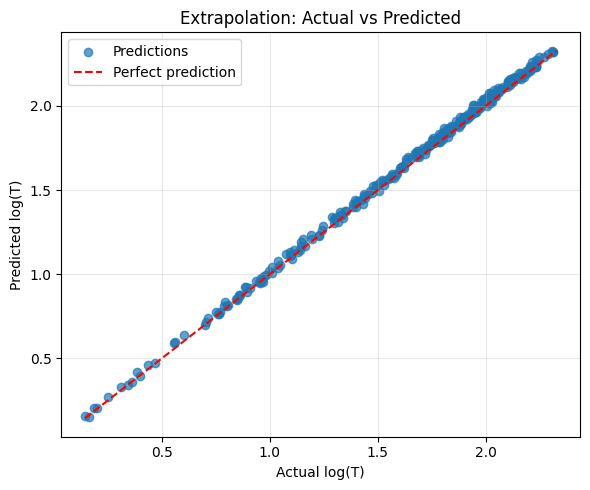

In [34]:
# Visualization
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.7, label="Predictions")

limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, "r--", label="Perfect prediction")

plt.xlabel("Actual log(T)")
plt.ylabel("Predicted log(T)")
plt.title("Extrapolation: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("extrapolation_predictions.png", dpi=300)
plt.show()

In [33]:
# Performance metrics
mse = np.mean((y_test - y_pred) ** 2)
mae = np.mean(np.abs(y_test - y_pred))
r2 = 1 - (np.sum((y_test - y_pred) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))

print("\nEXTRAPOLATION PERFORMANCE")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.5f}")
print(f"Mean Absolute Error (MAE): {mae:.5f}")
print(f"R-squared: {r2:.5f}")


EXTRAPOLATION PERFORMANCE
Root Mean Squared Error (RMSE): 0.02763
Mean Absolute Error (MAE): 0.02325
R-squared: 0.99709
